In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.lines import Line2D

# Đường dẫn tới file CSV
CSV_PATH = "../../outputs_evaluation/aggregated_k_shot_detailed.csv"

_df = pd.read_csv(CSV_PATH)
_df['Shots_Int'] = _df['Shots'].str.extract(r'(\d+)').astype(int)
_df['Pair'] = _df['Source'] + " ➔ " + _df['Target']

In [2]:
def plot_by_protocols(config_list, show_plots=True):
    """
    Vẽ biểu đồ so sánh F1-Score giữa các Protocol khác nhau (hoặc so sánh chéo Method/Backbone/Protocol).

    Args:
        config_list (list): Danh sách các chuỗi định danh "method/backbone/protocol"
                            (VD: ["tstcc/standard/full_finetuning", "tstcc/cnn_lstm/linear_probing"])
        show_plots (bool): True để hiển thị, False để đóng fig.
    """
    # 1. Parse cấu hình đầu vào
    parsed_configs = []
    for item in config_list:
        parts = item.split("/")
        if len(parts) == 3:
            method, backbone, protocol = parts
            # Nhãn hiển thị trên legend
            label = f"{method} ({backbone}) - {protocol}"
            parsed_configs.append({'method': method, 'backbone': backbone, 'protocol': protocol, 'label': label})
        else:
            print(f"⚠️ Bỏ qua config không đúng định dạng 'method/backbone/protocol': {item}")
            continue

    if not parsed_configs:
        return

    # 2. Lọc dữ liệu
    df_filtered = _df.copy()
    df_filtered['Config_Label'] = df_filtered['Method'] + " (" + df_filtered['Backbone'] + ") - " + df_filtered['Protocol']

    valid_labels = [c['label'] for c in parsed_configs]
    df_filtered = df_filtered[df_filtered['Config_Label'].isin(valid_labels)]

    if df_filtered.empty:
        print(f"⚠️ Không có dữ liệu cho các cấu hình: {config_list}")
        return

    # 3. Xác định các cặp (Source ➔ Target) có đủ dữ liệu cho TẤT CẢ các config
    # (Chỉ vẽ những cặp mà tất cả config đều có ít nhất 3 mốc k-shot để vẽ đường)
    valid_pairs = []
    for pair in df_filtered['Pair'].unique():
        df_pair = df_filtered[df_filtered['Pair'] == pair]
        # Đếm số lượng config có mặt trong cặp này
        configs_in_pair = df_pair['Config_Label'].unique()
        if len(configs_in_pair) == len(valid_labels):
            # Kiểm tra xem config nào cũng có >= 3 mốc k-shot
            if all(len(df_pair[df_pair['Config_Label'] == lbl]['Shots_Int'].unique()) >= 3 for lbl in valid_labels):
                valid_pairs.append(pair)

    if not valid_pairs:
        print("⚠️ Không có cặp (Source ➔ Target) nào chứa đủ dữ liệu cho tất cả các config yêu cầu.")
        return

    # 4. Sắp xếp cặp theo Target -> Source để hiển thị đẹp
    valid_pairs.sort(key=lambda x: (x.split(" ➔ ")[1], x.split(" ➔ ")[0]))

    # 5. Tính toán Grid (lưới) hiển thị
    n_pairs = len(valid_pairs)
    n_cols = min(3, n_pairs) # Tối đa 3 cột
    n_rows = (n_pairs + n_cols - 1) // n_cols

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5.5 * n_cols, 4.2 * n_rows + 2.5), sharey=True)
    axes = np.atleast_2d(axes)
    if axes.shape[1] != n_cols:
        axes = axes.T

    # 6. Cấu hình màu sắc và marker
    HIGH_CONTRAST_COLORS = ["#E63946", "#1D3557", "#2A9D8F", "#F4A261", "#8338EC", "#FF006E", "#457B9D", "#E76F51"]
    palette = HIGH_CONTRAST_COLORS[:len(valid_labels)]
    MARKERS = ['o', 's', 'v', 'D', '^', 'P', 'X', '*']

    # Map label -> màu và marker để đồng bộ
    label_color_map = dict(zip(valid_labels, palette))
    label_marker_map = dict(zip(valid_labels, MARKERS[:len(valid_labels)]))

    # 7. Vẽ từng Subplot
    for idx, pair in enumerate(valid_pairs):
        row_idx = idx // n_cols
        col_idx = idx % n_cols
        ax = axes[row_idx, col_idx]

        df_pair = df_filtered[df_filtered['Pair'] == pair]

        # Sử dụng hue='Config_Label' để phân biệt các cấu hình/protocol
        sns.lineplot(
            data=df_pair, x='Shots_Int', y='F1_Mean', hue='Config_Label',
            style='Config_Label', markers=label_marker_map, dashes=False,
            linewidth=2, markersize=7, ax=ax, legend=False,
            palette=label_color_map,
            hue_order=valid_labels,
            style_order=valid_labels
        )

        ax.set_title(f'{pair}', fontsize=11, fontweight='bold', pad=10)

        # Chỉ hiện nhãn trục ở các vị trí cần thiết
        if row_idx == n_rows - 1 or (idx + n_cols >= n_pairs):
            ax.set_xlabel('Số lượng K-Shot', fontsize=9)
        else:
            ax.set_xlabel('')

        if col_idx == 0:
            ax.set_ylabel('Macro F1-Score (%)', fontsize=9)
        else:
            ax.set_ylabel('')

        ax.set_xticks(sorted(df_pair['Shots_Int'].unique()))
        ax.set_ylim(10, 100)
        ax.grid(True, linestyle='--', alpha=0.6)

    # 8. Ẩn các ô trống (nếu số cặp không chia hết cho số cột)
    for idx in range(n_pairs, n_rows * n_cols):
        row_idx = idx // n_cols
        col_idx = idx % n_cols
        axes[row_idx, col_idx].axis('off')

    # 9. Tiêu đề và Legend
    fig.suptitle(f'So sánh F1-Score theo Protocol / Cấu hình', fontsize=18, fontweight='bold', y=0.97)

    custom_lines = [Line2D([0], [0], color=label_color_map[lbl], lw=2, marker=label_marker_map[lbl]) for lbl in valid_labels]

    # Tính số cột cho legend để không bị tràn
    ncol_legend = min(len(valid_labels), 4)

    fig.legend(custom_lines, valid_labels, title='Cấu hình & Protocol',
               loc='upper center', bbox_to_anchor=(0.5, 0.92),
               ncol=ncol_legend, fontsize=11, title_fontsize=12, frameon=True, borderpad=0.6, columnspacing=2.0)

    plt.subplots_adjust(top=0.80, bottom=0.08, left=0.06, right=0.98, wspace=0.18, hspace=0.45)

    if show_plots:
        plt.show()
    else:
        plt.close(fig)


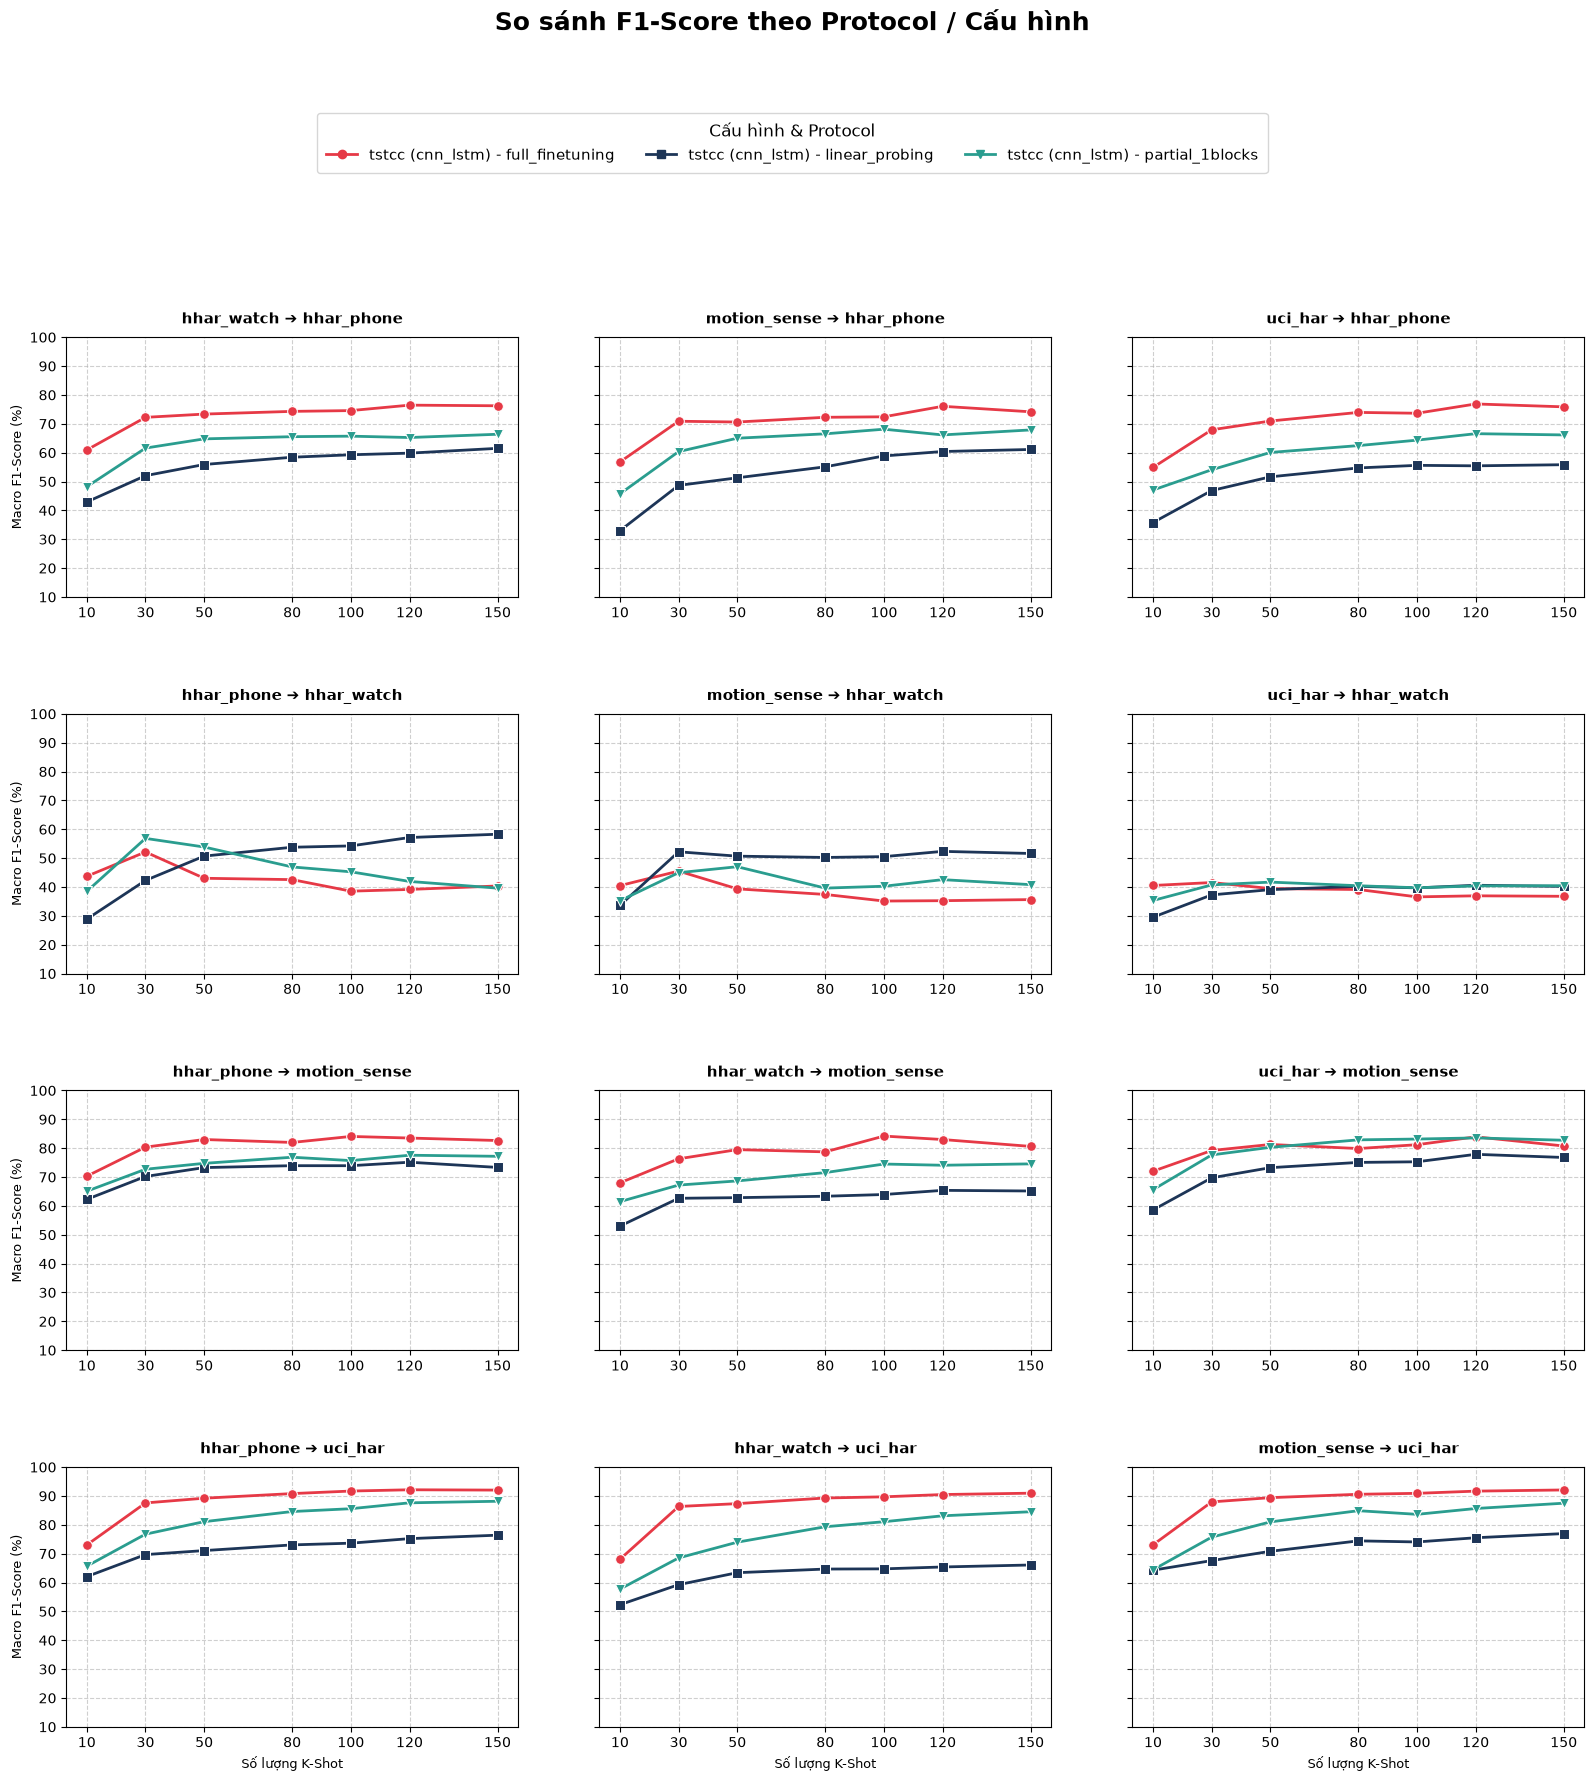

In [3]:
# So sánh các protocol của cùng 1 backbone
configs = [
    # "tstcc/standard_ts3/full_finetuning",
    # "tstcc/standard/linear_probing",
    "tstcc/cnn_lstm/full_finetuning",
    "tstcc/cnn_lstm/linear_probing",
    "tstcc/cnn_lstm/partial_1blocks",

]
plot_by_protocols(configs, show_plots=True)